Running bp_2_tau3_free ...
Running bp_2_tau3_fixed_1_7 ...
Running bp_2_tau4_free ...
Running bp_2_tau4_fixed_1_7 ...
Running bp_2_tau5_free ...
Running bp_2_tau5_fixed_1_7 ...
Running bp_2_tau6_free ...
Running bp_2_tau6_fixed_1_7 ...
Running bp_4_tau3_free ...
Running bp_4_tau3_fixed_1_7 ...
Running bp_4_tau4_free ...
Running bp_4_tau4_fixed_1_7 ...
Running bp_4_tau5_free ...
Running bp_4_tau5_fixed_1_7 ...
Running bp_4_tau6_free ...
Running bp_4_tau6_fixed_1_7 ...
Running bp_4_alt1_tau3_free ...
Running bp_4_alt1_tau3_fixed_1_7 ...
Running bp_4_alt1_tau4_free ...
Running bp_4_alt1_tau4_fixed_1_7 ...
Running bp_4_alt1_tau5_free ...
Running bp_4_alt1_tau5_fixed_1_7 ...
Running bp_4_alt1_tau6_free ...
Running bp_4_alt1_tau6_fixed_1_7 ...
Running bp_4_alt2_tau3_free ...
Running bp_4_alt2_tau3_fixed_1_7 ...
Running bp_4_alt2_tau4_free ...
Running bp_4_alt2_tau4_fixed_1_7 ...
Running bp_4_alt2_tau5_free ...
Running bp_4_alt2_tau5_fixed_1_7 ...
Running bp_4_alt2_tau6_free ...
Running bp_4_

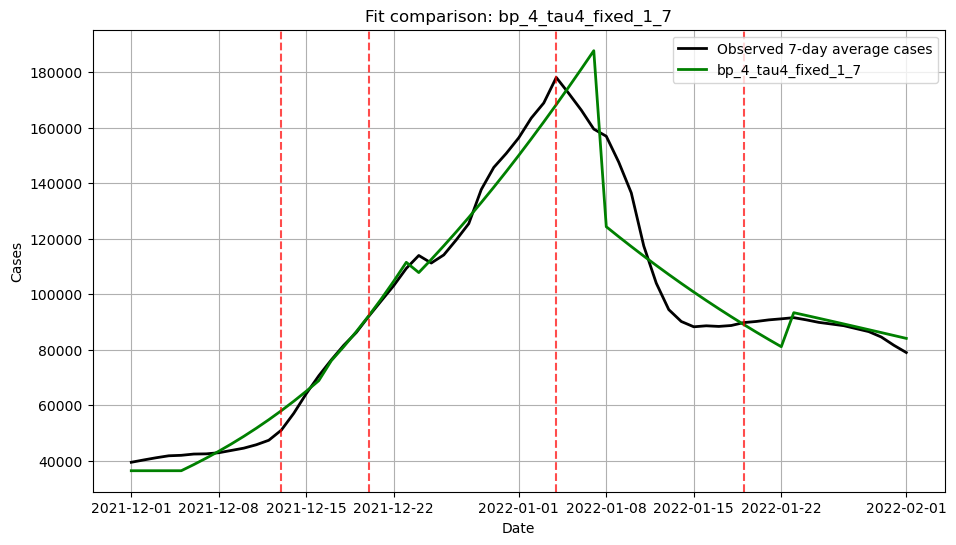

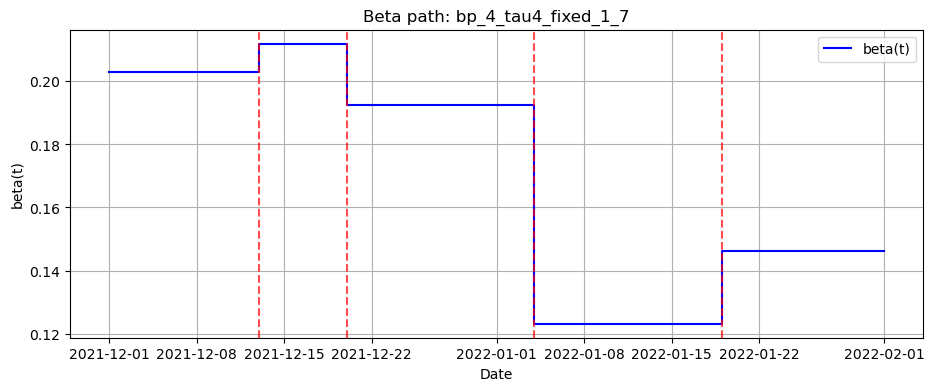

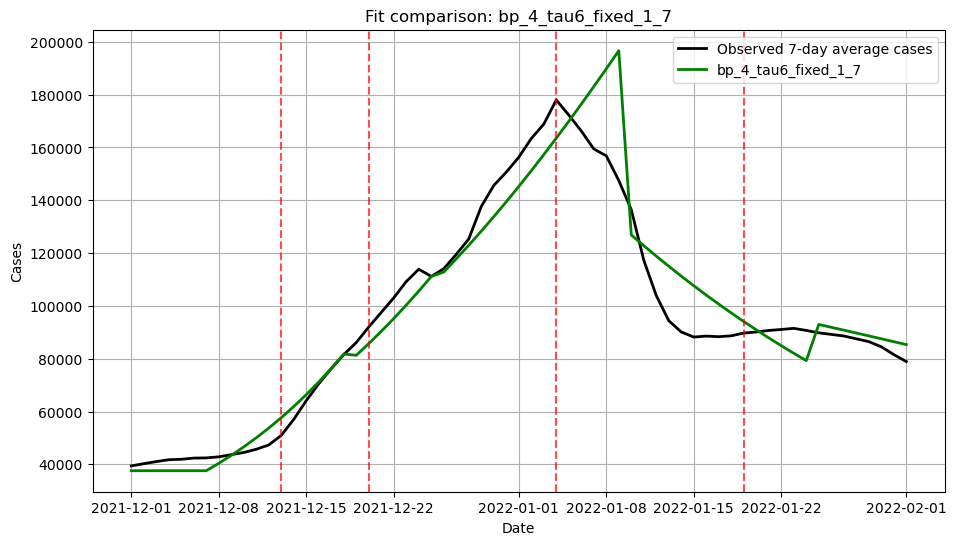

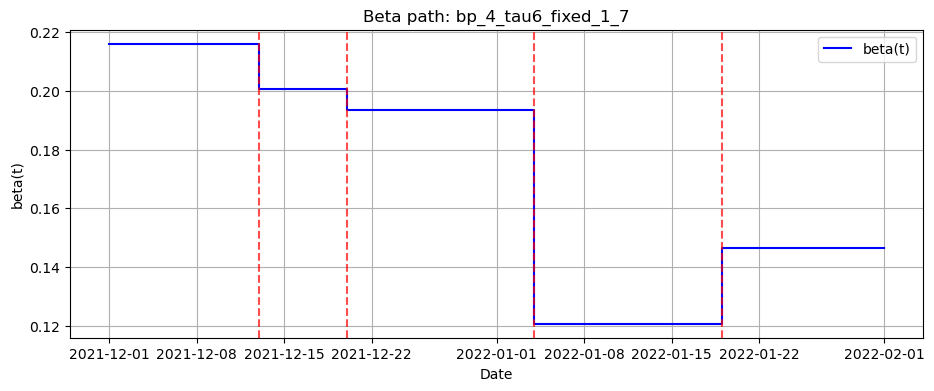

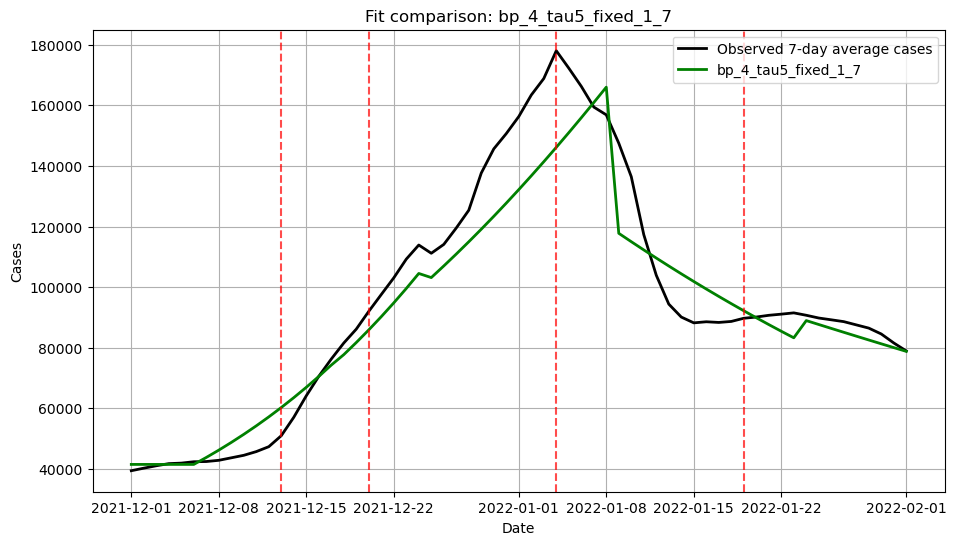

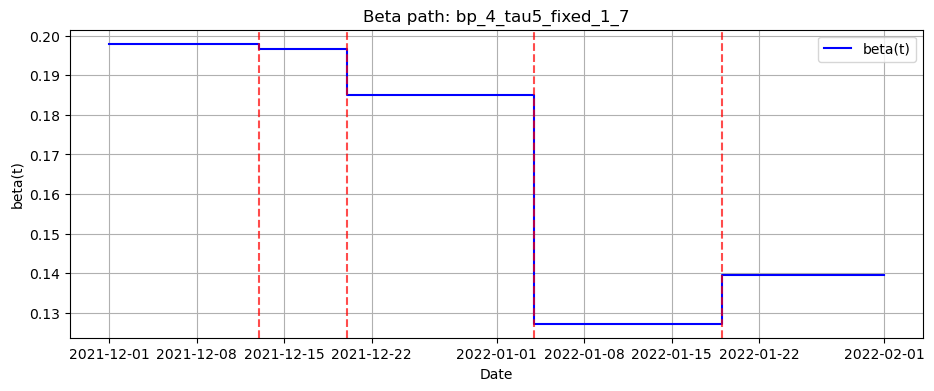

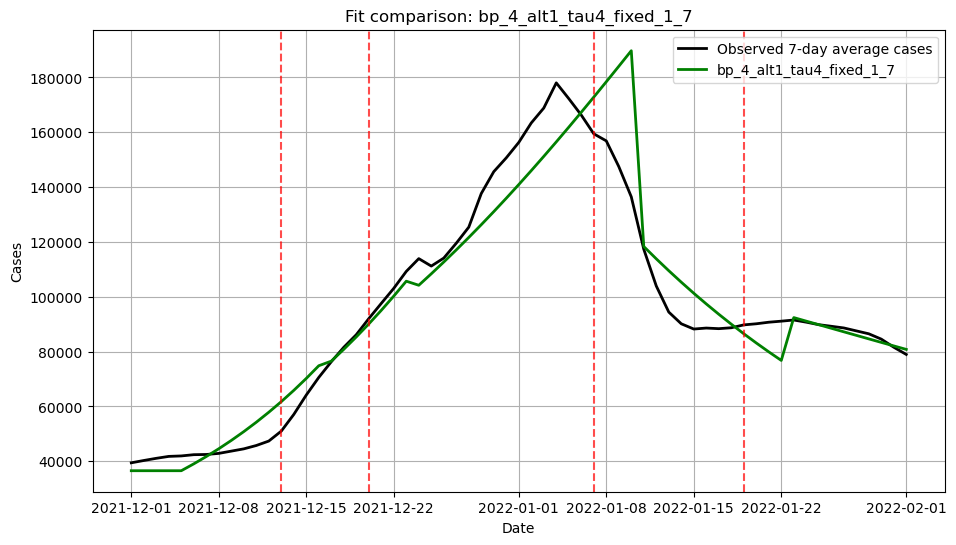

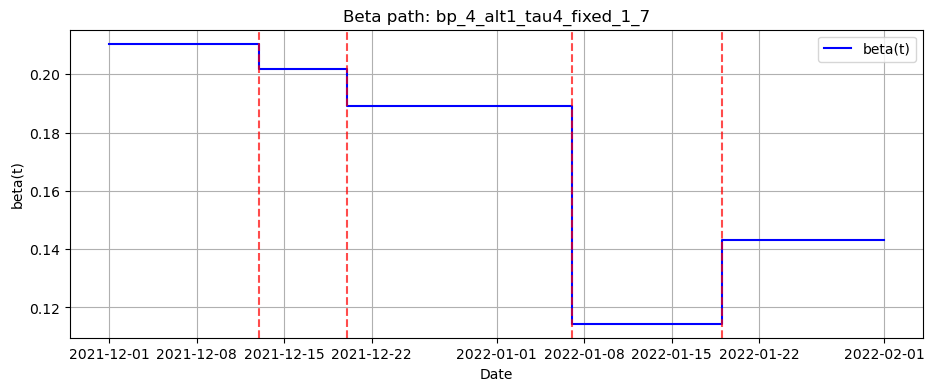

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# =========================
# 1. load data
# =========================
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

data = df_fit["cases_7d"].values.astype(float)
dates = df_fit["date"].values
t_eval = np.arange(len(data), dtype=float)

N = 67_000_000

# =========================
# 2. candidate breakpoint sets
# =========================
breakpoint_sets = {
    "bp_2": ["2021-12-13", "2022-01-19"],
    "bp_4": ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"],
    "bp_4_alt1": ["2021-12-13", "2021-12-20", "2022-01-07", "2022-01-19"],
    "bp_4_alt2": ["2021-12-13", "2021-12-20", "2022-01-10", "2022-01-19"],
}

tau_list = [3, 4, 5, 6]
gamma_modes = ["free", "fixed_1_7"]

# =========================
# 3. helper functions
# =========================
def get_break_indices(df_fit, break_dates):
    idx = []
    date_set = set(df_fit["date"])
    for d in break_dates:
        ts = pd.Timestamp(d)
        if ts not in date_set:
            raise ValueError(f"Breakpoint {d} not found in fitting window.")
        idx.append(int(np.where(df_fit["date"] == ts)[0][0]))
    return idx

def beta_piecewise_constant(tt, break_indices, beta_values):
    bounds = [0] + break_indices + [10**9]
    for k in range(len(beta_values)):
        if bounds[k] <= tt < bounds[k + 1]:
            return beta_values[k]
    return beta_values[-1]

def sir_rhs(t_now, y, break_indices, beta_values, gamma, N):
    S, I, R = y
    beta_t = beta_piecewise_constant(t_now, break_indices, beta_values)
    dSdt = -beta_t * S * I / N
    dIdt = beta_t * S * I / N - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

def simulate_sir_piecewise_constant(break_indices, beta_values, gamma, S0, I0, R0, N, t_eval):
    sol = solve_ivp(
        fun=lambda t_now, y: sir_rhs(t_now, y, break_indices, beta_values, gamma, N),
        t_span=(t_eval[0], t_eval[-1]),
        y0=[S0, I0, R0],
        t_eval=t_eval,
        method="RK45",
        rtol=1e-8,
        atol=1e-10
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    S = sol.y[0]
    I = sol.y[1]
    R = sol.y[2]
    beta_path = np.array([beta_piecewise_constant(tt, break_indices, beta_values) for tt in t_eval])
    incidence = beta_path * S * I / N
    return S, I, R, beta_path, incidence

def apply_fixed_delay(x, tau):
    tau = int(tau)
    y = np.empty_like(x)
    if tau <= 0:
        return x.copy()
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y

# =========================
# 4. single experiment runner
# =========================
def run_experiment(model_name, break_dates, tau_fixed, gamma_mode):
    break_indices = get_break_indices(df_fit, break_dates)
    n_seg = len(break_indices) + 1

    gamma_fixed = 1 / 7 if gamma_mode == "fixed_1_7" else None

    if gamma_mode == "free":
        x0 = [0.20] * n_seg + [0.10, 1.0, data[0] * 5.0]
        bounds = (
            [(1e-6, 1.5)] * n_seg +
            [(1e-6, 1.0)] +         # gamma
            [(1e-6, 100.0)] +       # rho
            [(1.0, 5_000_000.0)]    # I0
        )

        def loss_fn(params):
            beta_values = params[:n_seg]
            gamma = params[n_seg]
            rho = params[n_seg + 1]
            I0 = params[n_seg + 2]

            if np.any(np.array(beta_values) <= 0):
                return 1e20
            if gamma <= 0 or rho <= 0 or I0 <= 0 or I0 >= N:
                return 1e20

            R0 = 0.0
            S0 = N - I0 - R0

            try:
                S_fit, I_fit, R_fit, beta_path, incidence = simulate_sir_piecewise_constant(
                    break_indices, beta_values, gamma, S0, I0, R0, N, t_eval
                )
            except Exception:
                return 1e20

            delayed_incidence = apply_fixed_delay(incidence, tau_fixed)
            fitted_cases = rho * delayed_incidence

            if np.any(np.isnan(fitted_cases)) or np.any(np.isinf(fitted_cases)) or np.any(fitted_cases < 0):
                return 1e20

            eps = 1.0
            return np.mean((np.log(fitted_cases + eps) - np.log(data + eps)) ** 2)

        result = minimize(loss_fn, x0=x0, bounds=bounds, method="L-BFGS-B")
        if not result.success:
            return None

        best_params = result.x
        beta_values = best_params[:n_seg]
        gamma = best_params[n_seg]
        rho = best_params[n_seg + 1]
        I0 = best_params[n_seg + 2]

    else:
        x0 = [0.20] * n_seg + [1.0, data[0] * 5.0]
        bounds = (
            [(1e-6, 1.5)] * n_seg +
            [(1e-6, 100.0)] +       # rho
            [(1.0, 5_000_000.0)]    # I0
        )

        def loss_fn(params):
            beta_values = params[:n_seg]
            rho = params[n_seg]
            I0 = params[n_seg + 1]

            if np.any(np.array(beta_values) <= 0):
                return 1e20
            if rho <= 0 or I0 <= 0 or I0 >= N:
                return 1e20

            R0 = 0.0
            S0 = N - I0 - R0

            try:
                S_fit, I_fit, R_fit, beta_path, incidence = simulate_sir_piecewise_constant(
                    break_indices, beta_values, gamma_fixed, S0, I0, R0, N, t_eval
                )
            except Exception:
                return 1e20

            delayed_incidence = apply_fixed_delay(incidence, tau_fixed)
            fitted_cases = rho * delayed_incidence

            if np.any(np.isnan(fitted_cases)) or np.any(np.isinf(fitted_cases)) or np.any(fitted_cases < 0):
                return 1e20

            eps = 1.0
            return np.mean((np.log(fitted_cases + eps) - np.log(data + eps)) ** 2)

        result = minimize(loss_fn, x0=x0, bounds=bounds, method="L-BFGS-B")
        if not result.success:
            return None

        best_params = result.x
        beta_values = best_params[:n_seg]
        gamma = gamma_fixed
        rho = best_params[n_seg]
        I0 = best_params[n_seg + 1]

    R0 = 0.0
    S0 = N - I0 - R0

    S_fit, I_fit, R_fit, beta_path, incidence = simulate_sir_piecewise_constant(
        break_indices, beta_values, gamma, S0, I0, R0, N, t_eval
    )

    delayed_incidence = apply_fixed_delay(incidence, tau_fixed)
    fitted_cases = rho * delayed_incidence

    mse = np.mean((fitted_cases - data) ** 2)
    rmse = np.sqrt(mse)
    log_mse = np.mean((np.log(fitted_cases + 1.0) - np.log(data + 1.0)) ** 2)

    return {
        "model_name": model_name,
        "break_dates": break_dates,
        "tau": tau_fixed,
        "gamma_mode": gamma_mode,
        "n_breaks": len(break_dates),
        "beta_values": beta_values,
        "gamma": gamma,
        "rho": rho,
        "I0": I0,
        "MSE": mse,
        "RMSE": rmse,
        "log_MSE": log_mse,
        "fitted_cases": fitted_cases,
        "beta_path": beta_path,
    }

# =========================
# 5. run all experiments
# =========================
all_results = []

for bp_name, bp_dates in breakpoint_sets.items():
    for tau in tau_list:
        for gamma_mode in gamma_modes:
            model_name = f"{bp_name}_tau{tau}_{gamma_mode}"
            print(f"Running {model_name} ...")
            out = run_experiment(model_name, bp_dates, tau, gamma_mode)
            if out is not None:
                all_results.append(out)

# =========================
# 6. results table
# =========================
rows = []
for r in all_results:
    row = {
        "model_name": r["model_name"],
        "break_dates": str(r["break_dates"]),
        "tau": r["tau"],
        "gamma_mode": r["gamma_mode"],
        "n_breaks": r["n_breaks"],
        "gamma": r["gamma"],
        "rho": r["rho"],
        "I0": r["I0"],
        "MSE": r["MSE"],
        "RMSE": r["RMSE"],
        "log_MSE": r["log_MSE"],
    }
    beta_values = r["beta_values"]
    for i, b in enumerate(beta_values, start=1):
        row[f"beta{i}"] = b
    rows.append(row)

results_df = pd.DataFrame(rows)
results_df = results_df.sort_values("log_MSE").reset_index(drop=True)

print("\nTop models by log_MSE:")
print(results_df.head(10))

# optional save
results_df.to_csv("../results/model_comparison_piecewise_constant.csv", index=False)

# =========================
# 7. plot top k fits
# =========================
top_k = 4
top_models = results_df.head(top_k)["model_name"].tolist()

result_lookup = {r["model_name"]: r for r in all_results}

for name in top_models:
    r = result_lookup[name]

    plt.figure(figsize=(11, 6))
    plt.plot(df_fit["date"], data, label="Observed 7-day average cases", linewidth=2, color="black")
    plt.plot(df_fit["date"], r["fitted_cases"], label=name, linewidth=2, color="green")
    for d in r["break_dates"]:
        plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
    plt.title(f"Fit comparison: {name}")
    plt.xlabel("Date")
    plt.ylabel("Cases")
    plt.legend()
    plt.grid()
    plt.show()

    plt.figure(figsize=(11, 4))
    plt.step(df_fit["date"], r["beta_path"], where="post", label="beta(t)", color="blue")
    for d in r["break_dates"]:
        plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
    plt.title(f"Beta path: {name}")
    plt.xlabel("Date")
    plt.ylabel("beta(t)")
    plt.legend()
    plt.grid()
    plt.show()